In [1]:
import networkx as nx
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create a directed graph
G = nx.DiGraph()

# Add web pages as nodes
G.add_nodes_from(['A', 'B', 'C', 'D'])

# Add hyperlinks as directed edges
G.add_edges_from([
    ('B', 'A'),
    ('B', 'C'),
    ('C', 'A'),
    ('D', 'A'),
    ('D', 'B'),
    ('D', 'C')
])

print("Web pages:", G.nodes())
print("Links:", G.edges())

Web pages: ['A', 'B', 'C', 'D']
Links: [('B', 'A'), ('B', 'C'), ('C', 'A'), ('D', 'A'), ('D', 'B'), ('D', 'C')]


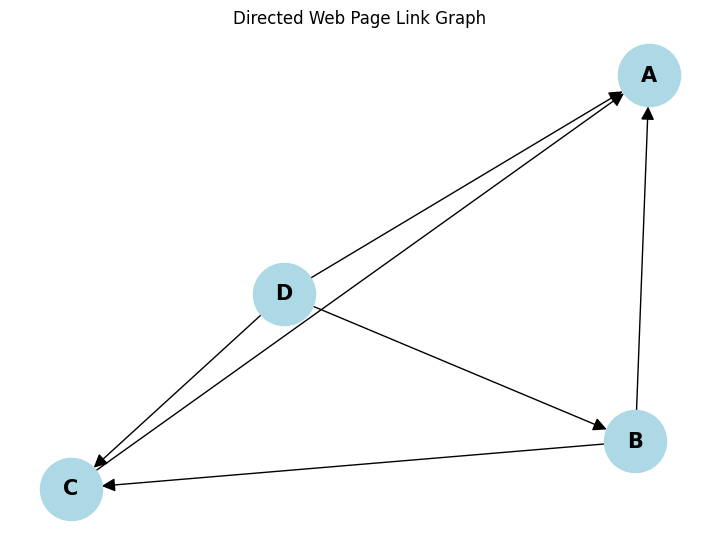

In [3]:
# Visualize the web page graph
plt.figure(figsize=(7, 5))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color='lightblue',
    node_size=2000,
    font_size=15,
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

plt.title("Directed Web Page Link Graph")
plt.show()

In [4]:
# Calculate PageRank
# Calculate PageRank using damping factor 0.85
pagerank = nx.pagerank(
    G,
    alpha=0.85,
    max_iter=100
)

print("PageRank Scores:")

for page, score in pagerank.items():
    print(page, ":", round(score, 4))

PageRank Scores:
A : 0.4514
B : 0.1712
C : 0.244
D : 0.1334


In [5]:
# display PageRank scores in descending order
# Sort pages according to PageRank score
sorted_pagerank = sorted(
    pagerank.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Pages ranked according to importance:\n")

for rank, (page, score) in enumerate(sorted_pagerank, start=1):
    print(f"Rank {rank}: Page {page} - Score: {score:.4f}")

Pages ranked according to importance:

Rank 1: Page A - Score: 0.4514
Rank 2: Page C - Score: 0.2440
Rank 3: Page B - Score: 0.1712
Rank 4: Page D - Score: 0.1334


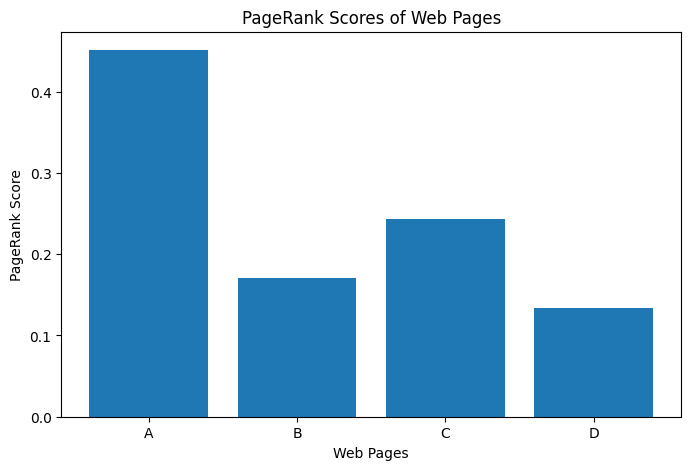

In [6]:
# Visualize PageRank scores
pages = list(pagerank.keys())
scores = list(pagerank.values())

plt.figure(figsize=(8, 5))

plt.bar(pages, scores)

plt.title("PageRank Scores of Web Pages")
plt.xlabel("Web Pages")
plt.ylabel("PageRank Score")

plt.show()

In [7]:
# Find the most important web page
important_page = max(pagerank, key=pagerank.get)

print("Most Important Web Page:", important_page)
print("Highest PageRank Score:", round(pagerank[important_page], 4))

Most Important Web Page: A
Highest PageRank Score: 0.4514


In [8]:
# verify the sum of PageRank scores
total_score = sum(pagerank.values())

print("Sum of all PageRank scores:", round(total_score, 4))

Sum of all PageRank scores: 1.0
